# MediSense-Cardio -- Full Sweep v2: Results Overview (Step 8)

**What this is:** the Step 8 results overview from `MediSense_Cardio_FullSweep_v2_Intervals.ipynb`, on its own.
The 10.5-hour sweep (50 real ECG pages x 31 damaged versions = 1,550 tests) has already finished and its
results are saved on Drive as `results_v2.csv`. This notebook only reads that file, so it needs no GPU and
no digitiser and runs in about a minute.

## Step 0 -- Mount Google Drive and load the finished results

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd

STUDY_DIR = '/content/drive/MyDrive/MediSense-Cardio-Study'
RESULTS_PATH = f'{STUDY_DIR}/results_v2.csv'

results_so_far = pd.read_csv(RESULTS_PATH)
N_TOTAL = 50 * 31  # 50 real records x (6 damage types x 5 levels + 1 clean)
AXES = ['blur', 'rotate', 'jpeg', 'resolution', 'brightness', 'gridcontrast']

Mounted at /content/drive


## Step 8 -- Results overview

Average heart-rate error for every damage type and level, and how many rows have a measured PR / QRS / QT / QTc.

In [2]:
print(f"{len(results_so_far)}/{N_TOTAL} variants have results so far.")

summary = results_so_far.groupby(['axis', 'level'])['diff_bpm'].agg(['mean', 'count']).round(3)
print("\nAverage heart-rate error by axis and level (higher level = more degradation):")
display(summary)
for col in ('diff_pr_ms', 'diff_qrs_ms', 'diff_qt_ms', 'diff_qtc_ms'):
    n_ok = int(results_so_far[col].notna().sum())
    mean_val = results_so_far[col].mean() if n_ok else float('nan')
    print(f"{col}: {n_ok}/{len(results_so_far)} rows have a value, mean={mean_val:.1f}ms" if n_ok else f"{col}: 0 rows have a value yet")

1550/1550 variants have results so far.

Average heart-rate error by axis and level (higher level = more degradation):


mean  count
axis         level              
blur         1      0.385     50
             2      0.735     50
             3      1.081     50
             4      2.995     49
             5      3.299     48
brightness   1      0.834     49
             2      1.159     48
             3      0.755     49
             4      0.391     50
             5      0.355     50
clean        0      0.521     50
gridcontrast 1      0.672     50
             2      0.495     50
             3      0.514     50
             4      0.524     50
             5      0.489     50
jpeg         1      0.806     48
             2      0.197     49
             3      0.364     49
             4      0.673     49
             5      0.497     49
resolution   1      0.340     49
             2      0.381     49
             3      0.994     49
             4      1.391     49
             5      7.843     49
rotate       1      0.483     49
             2      0.350     49
             3      0.498     48
             4      0.792     48
             5      0.970     44

diff_pr_ms: 1518/1550 rows have a value, mean=20.0ms
diff_qrs_ms: 1509/1550 rows have a value, mean=44.4ms
diff_qt_ms: 1509/1550 rows have a value, mean=31.2ms
diff_qtc_ms: 1509/1550 rows have a value, mean=34.8ms


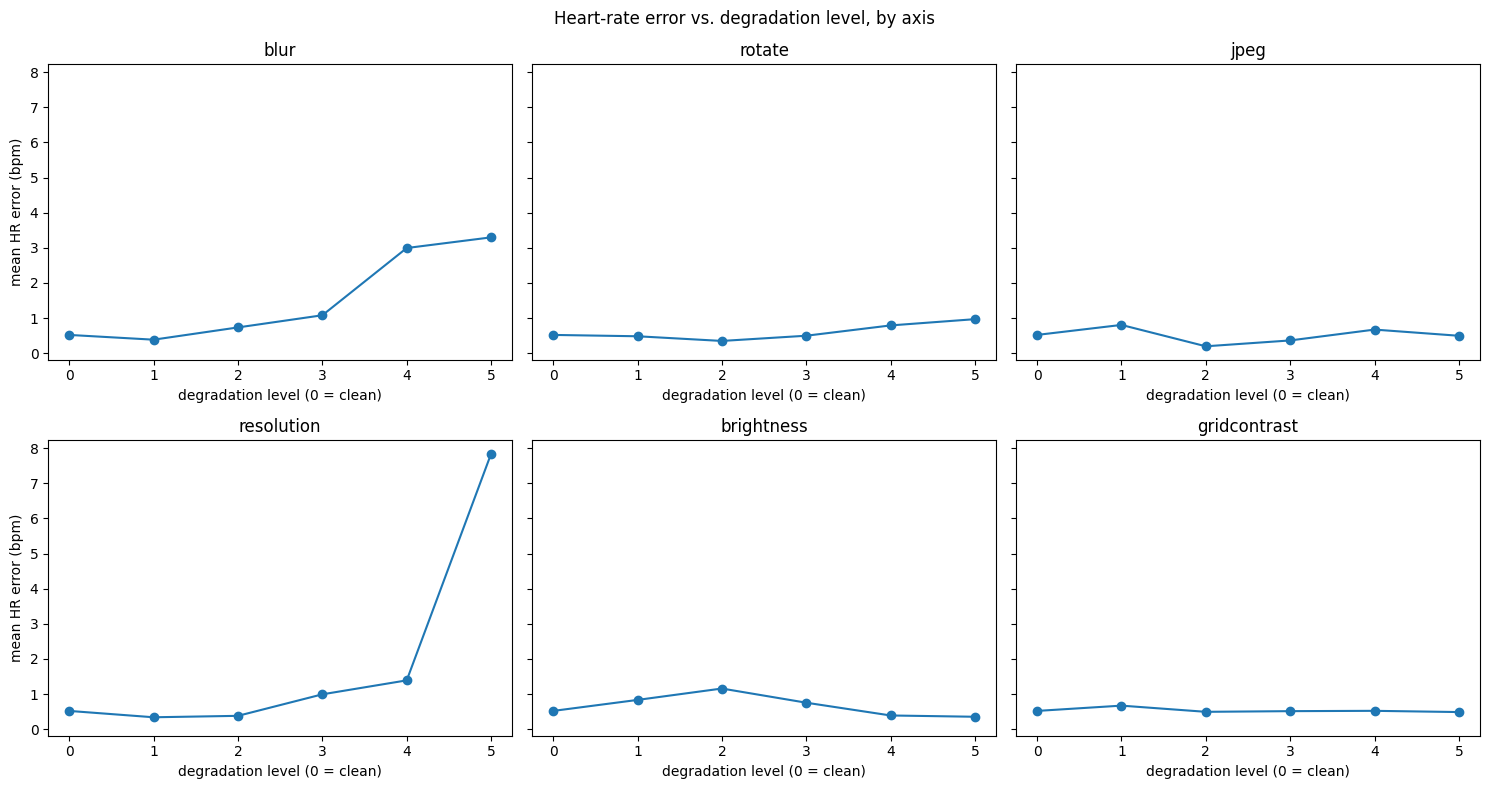

In [3]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
clean_mean = results_so_far[results_so_far['axis'] == 'clean']['diff_bpm'].mean()
for ax_name, ax in zip(AXES, axs.flat):
    sub = results_so_far[results_so_far['axis'] == ax_name]
    if len(sub) == 0:
        continue
    by_level = sub.groupby('level')['diff_bpm'].mean()
    levels_x = [0] + list(by_level.index)
    means_y = [clean_mean] + list(by_level.values)
    ax.plot(levels_x, means_y, marker='o')
    ax.set_title(ax_name)
    ax.set_xlabel('degradation level (0 = clean)')
axs[0, 0].set_ylabel('mean HR error (bpm)')
axs[1, 0].set_ylabel('mean HR error (bpm)')
fig.suptitle('Heart-rate error vs. degradation level, by axis')
plt.tight_layout()
plt.show()